# Transformer Alignment and Structure Figures

This notebook regenerates the key interpretation figures for the paper-trained transformer checkpoints in `./models/`. The figures compare unconstrained transformers with transformers trained under the symmetrized architecture across three task families: linear classification, semi-supervised classification, and Voronoi classification.

For each task family, the notebook reports three complementary views:

1. **Accuracy vs. context size.** Transformer accuracy is compared with task-appropriate classical baselines over varying input size $n$.
2. **Prediction alignment.** Each point is an evaluation prompt. The x-coordinate is the true-label probability averaged over unconstrained checkpoints, and the y-coordinate is the same quantity averaged over symmetrized checkpoints. The panel reports the linear-fit $R^2$.
3. **Weight structure.** The heatmaps show the collapsed $QK^T$ and value-output matrices for one deterministic representative checkpoint from each variant. Weight matrices are not averaged across seeds, since direct averages of independently trained weights need not be meaningful.

## Imports and Plot Style

The notebook uses PyTorch, NumPy, Matplotlib, and Seaborn. Checkpoints are loaded directly from disk, and the synthetic evaluation distributions are reconstructed from the saved training configs.

In [8]:
from pathlib import Path
import copy
import math
import warnings

import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import SymLogNorm
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import FuncFormatter

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.semi_supervised import LabelSpreading
from sklearn.preprocessing import StandardScaler

from util import load_yaml_to_conf

sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update({
    "figure.dpi": 200,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "lines.linewidth": 2.2,
    "axes.linewidth": 1.0,
})

DEVICE = "cpu"
EVAL_BSIZE = 10000
BASELINE_EVAL_BSIZE = 10000
BASELINE_VAL_BSIZE = 1000
DATA_SEED = 0
N_EVALS = (8, 16, 32, 64, 128)
MODEL_ROOT = Path("./models")

TASK_LABELS = {
    "linear_classification": "Linear classification",
    "semi_supervised": "Semi-supervised classification",
    "voronoicell": "Voronoi classification",
}

## Checkpoint Discovery

Paper training runs are stored as `./models/{task}/{variant}/{run_id}`, where `variant` is either `unconstrained` or `symmetrized`. The following cell discovers the available checkpoints and prints the runs included in the figures.

In [9]:
def discover_checkpoints(model_root=MODEL_ROOT):
    tasks = ["linear_classification", "semi_supervised", "voronoicell"]
    out = {}
    for task in tasks:
        out[task] = {}
        for variant in ["unconstrained", "symmetrized"]:
            run_dirs = sorted(
                p for p in (model_root / task / variant).glob("*")
                if (p / "config.yaml").exists() and (p / "state.pt").exists()
            )
            if not run_dirs:
                raise FileNotFoundError(f"No checkpoints found for {task}/{variant}")
            out[task][variant] = run_dirs
    return out

CHECKPOINTS = discover_checkpoints()

for task, variants in CHECKPOINTS.items():
    print(TASK_LABELS[task])
    for variant, paths in variants.items():
        seeds = []
        for p in paths:
            conf = load_yaml_to_conf(p / "config.yaml")
            seeds.append(conf.run.seed if "run" in conf and "seed" in conf.run else "?")
        print(f"  {variant:13s}: {len(paths)} runs, seeds={seeds}")

Linear classification
  unconstrained: 5 runs, seeds=[3, 1, 2, 4, 5]
  symmetrized  : 5 runs, seeds=[6, 8, 7, 9, 10]
Semi-supervised classification
  unconstrained: 5 runs, seeds=[2, 3, 1, 11, 10]
  symmetrized  : 5 runs, seeds=[4, 6, 5, 9, 8]
Voronoi classification
  unconstrained: 5 runs, seeds=[1, 2, 3, 7, 6]
  symmetrized  : 5 runs, seeds=[2, 3, 1, 4, 5]


## Model and Data Utilities

These utilities load transformer checkpoints, collapse the attention parameters into the matrices used for interpretation, and generate evaluation prompts from the same task distributions used during training.

In [10]:
def load_transformer(path, state="state.pt", device=DEVICE):
    path = Path(path)
    conf = load_yaml_to_conf(path / "config.yaml")
    state_obj = torch.load(path / state, map_location=device)
    state_dict = state_obj.get("model_state_dict", state_obj)

    n_heads = int(conf.model.n_head)
    n_embd = int(conf.model.n_embd)
    dim_head = n_embd

    weights_qk = []
    weights_v = []
    for layer in range(int(conf.model.n_layer)):
        q = state_dict[f"transformer.layers_attn.{layer}.projQ.weight"].view(n_heads, dim_head, n_embd)
        k = state_dict[f"transformer.layers_attn.{layer}.projK.weight"].view(n_heads, dim_head, n_embd)
        v = state_dict[f"transformer.layers_attn.{layer}.projV.weight"].view(n_heads, dim_head, n_embd)

        weights_qk.append(q.transpose(1, 2) @ k)

        final_key = f"transformer.layers_attn.{layer}.projFinal.weight"
        if final_key in state_dict:
            proj_final = state_dict[final_key].view(n_embd, n_heads, dim_head).transpose(0, 1)
            weights_v.append(v.transpose(1, 2) @ proj_final.transpose(1, 2))
        else:
            weights_v.append(v.transpose(1, 2))

    return (weights_qk, weights_v), conf


def transformer_forward(conf, transformer_weights, z):
    z = z.clone()
    outputs = [z]
    n_points = int(conf.task.points)
    n_embd = int(conf.model.n_embd)
    attn_mask = torch.ones(n_points, n_points, dtype=torch.bool, device=z.device)
    attn_mask[:, -1:] = False

    for qk, value in zip(*transformer_weights):
        qk = qk.to(z.device)
        value = value.to(z.device)
        attn = z[:, None, :, :] @ qk[None] @ z[:, None, :, :].transpose(-1, -2)
        attn = attn / math.sqrt(n_embd)
        attn.masked_fill_(~attn_mask[None, None], float("-inf"))
        attn = torch.nn.functional.softmax(attn, dim=-1)
        z = z + (attn @ z[:, None, :, :] @ value[None]).sum(dim=1)
        outputs.append(z)
    return outputs


def task_kwargs(conf):
    task = conf.task
    mode = str(task.mode)
    if mode == "semi_supervised":
        return {
            "eta": float(task.get("semi_eta", 0.0)),
            "n_labeled": int(task.get("semi_n_labeled", -1)),
            "replace_unlabeled_with_noise": bool(task.get("semi_replace_unlabeled_with_noise", False)),
        }
    if mode == "voronoicell":
        return {
            "margin": float(task.get("voronoi_margin", 0.0)),
            "noise": float(task.get("voronoi_noise", 0.0)),
            "n_labeled": int(task.get("voronoi_n_labeled", -1)),
            "replace_unlabeled_with_noise": bool(task.get("voronoi_replace_unlabeled_with_noise", False)),
            "site_scale": float(task.get("voronoi_site_scale", 1.0)),
            "x_scale": float(task.get("voronoi_x_scale", 1.0)),
            "normalize_sites": bool(task.get("voronoi_normalize_sites", False)),
        }
    return {
        "eta": 0.0,
        "n_labeled": -1,
        "replace_unlabeled_with_noise": False,
    }


def hide_context_labels(y_true, n_labeled, replace_unlabeled_with_noise, x):
    y = y_true.clone()
    bsize, n_points, _ = y.shape
    if n_points > 1 and n_labeled >= 0:
        keep = torch.zeros(bsize, n_points, device=y.device, dtype=torch.bool)
        keep[:, -1] = True
        if n_labeled > 0:
            scores = torch.rand(bsize, n_points, device=y.device)
            scores[:, -1] = -1.0
            keep.scatter_(1, scores.argsort(dim=-1, descending=True)[:, :n_labeled], True)
        hide = ~keep
        hide[:, -1] = False
        y = y.masked_fill(hide.unsqueeze(-1), 0.0)

    if replace_unlabeled_with_noise:
        unlabeled = y.abs().sum(dim=-1) == 0
        x = torch.where(unlabeled.unsqueeze(-1), torch.randn_like(x), x)
    return x, y


def make_linear_data(conf, bsize, device=DEVICE):
    dtype = torch.float32
    task = conf.task
    kwargs = task_kwargs(conf)
    n_points = int(task.points)
    n_dims = int(task.dims)
    n_classes = int(task.n_classes)

    w = torch.randn(bsize, n_dims, n_classes, dtype=dtype, device=device)
    w = w / (w.norm(dim=1, keepdim=True) + 1e-8)
    x = torch.randn(bsize, n_points, n_dims, dtype=dtype, device=device)
    class_idx = (x @ w).argmax(dim=-1)

    eta = float(kwargs["eta"])
    if eta != 0.0:
        batch_idx = torch.arange(bsize, device=device)[:, None]
        w_selected = w.transpose(1, 2)[batch_idx, class_idx]
        x = x + eta * w_selected

    y_true = torch.zeros(bsize, n_points, n_classes, dtype=dtype, device=device)
    y_true.scatter_(2, class_idx.unsqueeze(-1), 1.0)
    x, y = hide_context_labels(
        y_true,
        n_labeled=int(kwargs["n_labeled"]),
        replace_unlabeled_with_noise=bool(kwargs["replace_unlabeled_with_noise"]),
        x=x,
    )

    z = torch.cat([x, y], dim=-1)
    z[:, -1, -n_classes:] = 0.0
    return z.cpu(), y_true[:, -1, :].cpu()


def make_voronoi_data(conf, bsize, device=DEVICE):
    dtype = torch.float32
    task = conf.task
    kwargs = task_kwargs(conf)
    n_points = int(task.points)
    n_dims = int(task.dims)
    n_classes = int(task.n_classes)

    C = kwargs["site_scale"] * torch.randn(bsize, n_dims, n_classes, dtype=dtype, device=device)
    if kwargs["normalize_sites"]:
        C = C / (C.norm(dim=1, keepdim=True) + 1e-8)
    C_T = C.transpose(1, 2)

    x = kwargs["x_scale"] * torch.randn(bsize, n_points, n_dims, dtype=dtype, device=device)
    x2 = (x * x).sum(dim=-1, keepdim=True)
    c2 = (C_T * C_T).sum(dim=-1).unsqueeze(1)
    d2 = x2 + c2 - 2.0 * (x @ C)
    class_idx = d2.argmin(dim=-1)

    margin = float(kwargs["margin"])
    if margin > 0:
        c_sel = (
            C_T[:, None].expand(-1, n_points, -1, -1)
            .gather(2, class_idx[:, :, None, None].expand(-1, -1, 1, n_dims))
            .squeeze(2)
        )
        x = x + margin * c_sel

    y_true = torch.zeros(bsize, n_points, n_classes, dtype=dtype, device=device)
    y_true.scatter_(2, class_idx.unsqueeze(-1), 1.0)

    noise = float(kwargs["noise"])
    y = y_true.clone()
    if noise > 0:
        flip = torch.rand(bsize, n_points, device=device) < noise
        wrong = torch.randint(0, n_classes - 1, (bsize, n_points), device=device)
        wrong = wrong + (wrong >= class_idx).long()
        noisy_idx = torch.where(flip, wrong, class_idx)
        y.zero_()
        y.scatter_(2, noisy_idx.unsqueeze(-1), 1.0)

    x, y = hide_context_labels(
        y,
        n_labeled=int(kwargs["n_labeled"]),
        replace_unlabeled_with_noise=bool(kwargs["replace_unlabeled_with_noise"]),
        x=x,
    )

    z = torch.cat([x, y], dim=-1)
    z[:, -1, -n_classes:] = 0.0
    return z.cpu(), y_true[:, -1, :].cpu()


def make_data(conf, bsize=EVAL_BSIZE, seed=DATA_SEED, device=DEVICE):
    torch.manual_seed(seed)
    np.random.seed(seed)
    if str(conf.task.mode) == "voronoicell":
        return make_voronoi_data(conf, bsize, device=device)
    return make_linear_data(conf, bsize, device=device)


def query_logits(conf, weights, z):
    n_classes = int(conf.task.n_classes)
    return transformer_forward(conf, weights, z)[-1][:, -1, -n_classes:]


def true_class_probability(logits, y_true):
    idx = y_true.argmax(dim=-1)
    probs = torch.softmax(logits, dim=-1)
    return probs[torch.arange(probs.shape[0], device=probs.device), idx]


def accuracy_from_logits(logits, y_true):
    return float((logits.argmax(dim=-1) == y_true.argmax(dim=-1)).float().mean())

## Plotting and Baseline Utilities

Prediction alignment is computed after averaging predictions across checkpoints within each variant. Weight-structure panels use a single representative checkpoint per variant, chosen deterministically as the first sorted run. Accuracy-vs-context-size panels compare transformer checkpoints with task-appropriate classical baselines.

Classical baselines are evaluated on `BASELINE_EVAL_BSIZE` prompts by default because they fit a separate model or graph for each prompt. Transformer and alignment figures use `EVAL_BSIZE`.


In [11]:
def r2_score(y, yhat):
    y = np.asarray(y, dtype=float)
    yhat = np.asarray(yhat, dtype=float)
    ss_res = np.sum((y - yhat) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    return 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan


def mean_true_probability(paths, z, y_true):
    vals = []
    accs = []
    for path in paths:
        weights, conf = load_transformer(path)
        logits = query_logits(conf, weights, z)
        vals.append(true_class_probability(logits, y_true).detach().cpu().numpy())
        accs.append(accuracy_from_logits(logits, y_true))
    return np.stack(vals, axis=0).mean(axis=0), float(np.mean(accs))


def plot_alignment_scatter(task_name, paths_unconstrained, paths_symmetrized, bsize=EVAL_BSIZE, seed=DATA_SEED):
    _, conf = load_transformer(paths_unconstrained[0])
    z, y_true = make_data(conf, bsize=bsize, seed=seed)

    mean_u, acc_u = mean_true_probability(paths_unconstrained, z, y_true)
    mean_s, acc_s = mean_true_probability(paths_symmetrized, z, y_true)

    m = np.isfinite(mean_u) & np.isfinite(mean_s)
    x = mean_u[m]
    y = mean_s[m]
    slope, intercept = np.polyfit(x, y, deg=1)
    yhat = slope * x + intercept
    r2 = r2_score(y, yhat)

    fig, ax = plt.subplots(figsize=(4.2, 3.4))
    ax.scatter(x, y, s=16, alpha=0.55, edgecolors="none", label="Evaluation prompts")
    xs = np.linspace(float(x.min()), float(x.max()), 200)
    ax.plot(xs, slope * xs + intercept, "k--", linewidth=2.0, label="Linear fit")
    ax.set_xlabel("Mean true-class probability\n(unconstrained)")
    ax.set_ylabel("Mean true-class probability\n(symmetrized)")
    ax.set_title(TASK_LABELS[task_name])
    ax.text(
        0.04, 0.96,
        f"$R^2$ = {r2:.3f}",
        transform=ax.transAxes,
        ha="left", va="top", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.85", alpha=0.95),
    )
    ax.grid(True, linewidth=0.8, alpha=0.55)
    ax.legend(loc="lower right", frameon=True, framealpha=0.95)
    plt.tight_layout()
    plt.show()

    return {
        "task": task_name,
        "r2": float(r2),
        "slope": float(slope),
        "intercept": float(intercept),
        "acc_unconstrained": acc_u,
        "acc_symmetrized": acc_s,
    }


def representative_weights(paths):
    """Load one deterministic representative checkpoint for heatmap visualization."""
    path = sorted(Path(p) for p in paths)[0]
    weights, conf = load_transformer(path)
    weights = ([t.detach().cpu() for t in weights[0]], [t.detach().cpu() for t in weights[1]])
    return weights, conf, path

def _matrix_np(t):
    arr = t.detach().cpu().numpy()
    return arr[0] if arr.ndim == 3 else arr


def plot_weight_heatmaps(task_name, paths_unconstrained, paths_symmetrized):
    (qks_u, vals_u), _, path_u = representative_weights(paths_unconstrained)
    (qks_s, vals_s), _, path_s = representative_weights(paths_symmetrized)
    n_layers = len(qks_u)

    all_mats = qks_u + vals_u + qks_s + vals_s
    absmax = max(float(np.abs(_matrix_np(t)).max()) for t in all_mats)
    absmax = max(absmax, 1e-8)
    norm = SymLogNorm(linthresh=0.1 * absmax, linscale=1.0, vmin=-absmax, vmax=absmax, base=10)
    cmap = "seismic"

    gap_cols = 1
    fig = plt.figure(figsize=(2.0 * n_layers, 2.65))
    gs = fig.add_gridspec(
        2, 2 * n_layers + gap_cols,
        width_ratios=[1] * n_layers + [0.5] + [1] * n_layers,
        wspace=0.06,
        hspace=-0.22,
        left=0.012, right=0.90, top=0.86, bottom=0.13,
    )
    hm_kw = dict(cbar=False, square=True, xticklabels=False, yticklabels=False)

    def draw(ax, mat):
        sns.heatmap(_matrix_np(mat), ax=ax, cmap=cmap, norm=norm, **hm_kw)
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(0.8)
            spine.set_edgecolor("0.35")

    for layer in range(n_layers):
        ax_qk_u = fig.add_subplot(gs[0, layer])
        ax_v_u = fig.add_subplot(gs[1, layer])
        col_s = n_layers + gap_cols + layer
        ax_qk_s = fig.add_subplot(gs[0, col_s])
        ax_v_s = fig.add_subplot(gs[1, col_s])

        draw(ax_qk_u, qks_u[layer])
        draw(ax_v_u, vals_u[layer])
        draw(ax_qk_s, qks_s[layer])
        draw(ax_v_s, vals_s[layer])

        ax_qk_u.set_title(f"Layer {layer + 1}", pad=3, fontweight="normal")
        ax_qk_s.set_title(f"Layer {layer + 1}", pad=3, fontweight="normal")
        if layer == 0:
            ax_qk_u.set_ylabel("QK")
            ax_v_u.set_ylabel("V")
            ax_qk_s.set_ylabel("QK")
            ax_v_s.set_ylabel("V")

    fig.suptitle(f"{TASK_LABELS[task_name]}: representative attention weights", y=0.985, fontsize=13)
    fig.text(0.235, 0.030, f"Unconstrained\n{path_u.name}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
    fig.text(0.685, 0.030, f"Symmetrized\n{path_s.name}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

    cax = fig.add_axes([0.925, 0.28, 0.016, 0.44])
    cb = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), cax=cax)
    ticks = [-10, -2, 0, 2, 10]
    ticks = [t for t in ticks if -absmax <= t <= absmax]
    if ticks:
        cb.set_ticks(ticks)
    cb.minorticks_off()
    cb.formatter = FuncFormatter(lambda x, pos: f"{int(x)}" if float(x).is_integer() else f"{x:g}")
    cb.update_ticks()
    plt.show()



def set_context_size(conf, n_context):
    conf_eval = copy.deepcopy(conf)
    conf_eval.task.points = int(n_context) + 1
    return conf_eval


def transformer_accuracy_curve(paths, n_evals=N_EVALS, bsize=EVAL_BSIZE, seed=DATA_SEED):
    rows = []
    _, conf0 = load_transformer(paths[0])
    for n in n_evals:
        conf_eval = set_context_size(conf0, n)
        z, y_true = make_data(conf_eval, bsize=bsize, seed=seed)
        values = []
        for path in paths:
            weights, conf = load_transformer(path)
            conf = set_context_size(conf, n)
            values.append(accuracy_from_logits(query_logits(conf, weights, z), y_true))
        values = np.asarray(values, dtype=float)
        rows.append({
            "n": int(n),
            "mean": float(values.mean()),
            "lo": float(values.mean() - values.std(ddof=1)) if values.size > 1 else float(values.mean()),
            "hi": float(values.mean() + values.std(ddof=1)) if values.size > 1 else float(values.mean()),
        })
    return rows


def _episode_arrays(z, y_true):
    z_np = z.detach().cpu().numpy() if isinstance(z, torch.Tensor) else np.asarray(z)
    y_np = y_true.detach().cpu().numpy() if isinstance(y_true, torch.Tensor) else np.asarray(y_true)
    B, N, D = z_np.shape
    K = y_np.shape[-1]
    d = D - K
    X = z_np[:, :, :d]
    Y = z_np[:, :, d:]
    yq = y_np.argmax(axis=-1).astype(int)
    return X, Y, yq, K


def _expand_to_K(vec_small, classes, K):
    out = np.zeros(K, dtype=float)
    out[np.asarray(classes, dtype=int)] = vec_small
    return out


def _svm_proba_full(svm, x, K):
    scores = np.asarray(svm.decision_function(x[None, :])).reshape(-1)
    if scores.shape[0] == K:
        raw = scores
        classes = np.arange(K)
    else:
        raw = scores
        classes = svm.classes_
    raw = raw - raw.max()
    p_small = np.exp(raw) / np.exp(raw).sum()
    return _expand_to_K(p_small, classes, K)


def evaluate_logreg_svm(z, y_true, C_logreg=1.0, C_svm=1.0):
    X, Y, yq, K = _episode_arrays(z, y_true)
    B = X.shape[0]
    preds_lr = np.empty(B, dtype=int)
    preds_svm = np.empty(B, dtype=int)
    for b in range(B):
        labeled = Y[b, :-1].sum(axis=-1) == 1.0
        X_lab = X[b, :-1][labeled]
        y_lab = Y[b, :-1][labeled].argmax(axis=-1).astype(int)
        uniq = np.unique(y_lab)
        if uniq.size == 1:
            preds_lr[b] = preds_svm[b] = int(uniq[0])
            continue
        lr = LogisticRegression(C=float(C_logreg), solver="lbfgs", max_iter=400)
        lr.fit(X_lab, y_lab)
        preds_lr[b] = int(lr.predict(X[b, -1][None, :])[0])
        svm = LinearSVC(C=float(C_svm), max_iter=8000)
        svm.fit(X_lab, y_lab)
        preds_svm[b] = int(svm.predict(X[b, -1][None, :])[0])
    return {
        "Logistic regression": float(np.mean(preds_lr == yq)),
        "Linear SVM": float(np.mean(preds_svm == yq)),
    }


def tune_supervised_baselines(conf, n_context, metric_bsize=BASELINE_VAL_BSIZE, seed=DATA_SEED):
    c_grid = [1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0, 1000.0]
    conf_eval = set_context_size(conf, n_context)
    z_val, y_val = make_data(conf_eval, bsize=metric_bsize, seed=seed + 17)
    best_lr = max(c_grid, key=lambda c: evaluate_logreg_svm(z_val, y_val, C_logreg=c, C_svm=1.0)["Logistic regression"])
    best_svm = max(c_grid, key=lambda c: evaluate_logreg_svm(z_val, y_val, C_logreg=best_lr, C_svm=c)["Linear SVM"])
    return {"C_logreg": float(best_lr), "C_svm": float(best_svm)}


def _default_label_spread_hp(N):
    k = int(np.clip(np.ceil(np.sqrt(N)), 5, 30))
    k = min(k, max(2, N - 1))
    return {
        "Label spreading (kNN)": {"kernel": "knn", "n_neighbors": k, "alpha": 0.2, "max_iter": 2000, "tol": 1e-4},
        "Label spreading (RBF)": {"kernel": "rbf", "gamma": 1.0, "alpha": 0.3, "max_iter": 3000, "tol": 1e-4},
    }


def _label_spread_predict(Xs, y_partial, K, hp):
    present = np.unique(y_partial[y_partial != -1])
    if present.size < 2:
        c = int(present[0]) if present.size == 1 else 0
        p = np.zeros(K, dtype=float)
        p[c] = 1.0
        return c
    kwargs = dict(kernel=hp["kernel"], alpha=float(hp["alpha"]), max_iter=int(hp["max_iter"]), tol=float(hp["tol"]))
    if hp["kernel"] == "knn":
        kwargs["n_neighbors"] = int(hp["n_neighbors"])
    else:
        kwargs["gamma"] = float(hp["gamma"])
    ls = LabelSpreading(**kwargs)
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="invalid value encountered in divide", category=RuntimeWarning)
        ls.fit(Xs, y_partial)
    p = np.asarray(ls.predict_proba(Xs[[-1]])[0], dtype=float)
    p = np.nan_to_num(p, nan=0.0, posinf=0.0, neginf=0.0)
    return int(ls.classes_[int(np.argmax(p))])


def evaluate_label_spreading(z, y_true):
    X, Y, yq, K = _episode_arrays(z, y_true)
    B, N = X.shape[:2]
    hp_by_name = _default_label_spread_hp(N)
    preds = {name: np.empty(B, dtype=int) for name in hp_by_name}
    for b in range(B):
        labeled = Y[b, :-1].sum(axis=-1) == 1.0
        y_lab = Y[b, :-1][labeled].argmax(axis=-1).astype(int)
        y_partial = np.full(N, -1, dtype=int)
        y_partial[:-1][labeled] = y_lab
        Xs = StandardScaler(with_mean=True, with_std=True).fit_transform(X[b])
        for name, hp in hp_by_name.items():
            preds[name][b] = _label_spread_predict(Xs, y_partial, K, hp)
    return {name: float(np.mean(pred == yq)) for name, pred in preds.items()}


def evaluate_1nn(z, y_true):
    X, Y, yq, _ = _episode_arrays(z, y_true)
    B = X.shape[0]
    pred = np.empty(B, dtype=int)
    for b in range(B):
        labeled = Y[b, :-1].sum(axis=-1) == 1.0
        X_lab = X[b, :-1][labeled]
        y_lab = Y[b, :-1][labeled].argmax(axis=-1).astype(int)
        dist2 = ((X_lab - X[b, -1][None, :]) ** 2).sum(axis=-1)
        pred[b] = int(y_lab[int(np.argmin(dist2))])
    return {"1-NN": float(np.mean(pred == yq))}


def baseline_accuracy_curve(task_name, conf, n_evals=N_EVALS, bsize=EVAL_BSIZE, seed=DATA_SEED):
    rows = []
    for n in n_evals:
        conf_eval = set_context_size(conf, n)
        z, y_true = make_data(conf_eval, bsize=bsize, seed=seed)
        if task_name == "linear_classification":
            hp = tune_supervised_baselines(conf, n, seed=seed)
            vals = evaluate_logreg_svm(z, y_true, **hp)
        elif task_name == "semi_supervised":
            vals = evaluate_label_spreading(z, y_true)
        elif task_name == "voronoicell":
            vals = evaluate_1nn(z, y_true)
        else:
            raise ValueError(task_name)
        for method, acc in vals.items():
            rows.append({"n": int(n), "method": method, "accuracy": float(acc)})
    return rows


def plot_accuracy_vs_n(task_name, paths_unconstrained, paths_symmetrized, bsize=EVAL_BSIZE, baseline_bsize=BASELINE_EVAL_BSIZE, seed=DATA_SEED):
    _, conf = load_transformer(paths_unconstrained[0])
    curves = {
        "Transformer (unconstrained)": transformer_accuracy_curve(paths_unconstrained, bsize=bsize, seed=seed),
        "Transformer (symmetrized)": transformer_accuracy_curve(paths_symmetrized, bsize=bsize, seed=seed),
    }
    baselines = baseline_accuracy_curve(task_name, conf, bsize=baseline_bsize, seed=seed)

    fig, ax = plt.subplots(figsize=(4.6, 3.3))
    for label, rows in curves.items():
        ns = np.array([r["n"] for r in rows])
        mean = np.array([r["mean"] for r in rows])
        lo = np.array([r["lo"] for r in rows])
        hi = np.array([r["hi"] for r in rows])
        ax.plot(ns, mean, marker="o", label=label)
        ax.fill_between(ns, lo, hi, alpha=0.12)

    methods = sorted({r["method"] for r in baselines})
    for method in methods:
        rows = [r for r in baselines if r["method"] == method]
        ax.plot([r["n"] for r in rows], [r["accuracy"] for r in rows], marker="s", linestyle="--", linewidth=2.0, label=method)

    ax.set_title(f"{TASK_LABELS[task_name]}: accuracy vs. context size")
    ax.set_xlabel("Context size $n$")
    ax.set_ylabel("Accuracy")
    ax.set_xticks(list(N_EVALS))
    ax.set_ylim(0.0, 1.02)
    ax.grid(True, linewidth=0.8, alpha=0.55)
    ax.legend(loc="best", frameon=True, framealpha=0.95)
    plt.tight_layout()
    plt.show()

    return {"transformers": curves, "baselines": baselines}


def plot_task_report(task_name, bsize=EVAL_BSIZE, baseline_bsize=BASELINE_EVAL_BSIZE, seed=DATA_SEED):
    paths_u = CHECKPOINTS[task_name]["unconstrained"]
    paths_s = CHECKPOINTS[task_name]["symmetrized"]
    perf = plot_accuracy_vs_n(task_name, paths_u, paths_s, bsize=bsize, baseline_bsize=baseline_bsize, seed=seed)
    alignment = plot_alignment_scatter(task_name, paths_u, paths_s, bsize=bsize, seed=seed)
    plot_weight_heatmaps(task_name, paths_u, paths_s)
    return {"task": task_name, "performance": perf, "alignment": alignment}


## Linear Classification

This section compares unconstrained and symmetrized transformers on the linear classification task. The baseline panel uses logistic regression and linear SVM classifiers trained on the labeled context points; each baseline tunes its regularization parameter `C` over a fixed logarithmic grid at each context size.

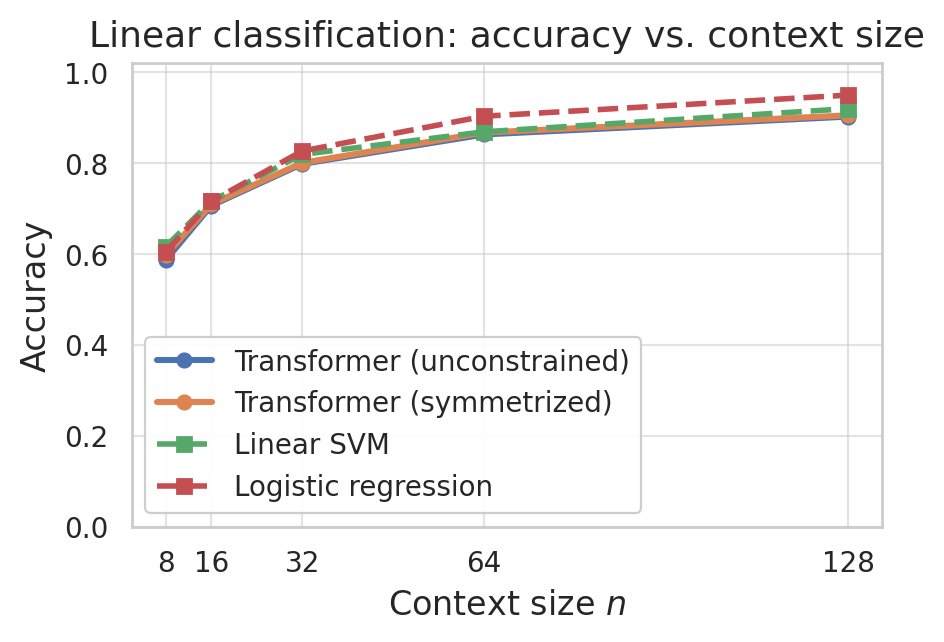

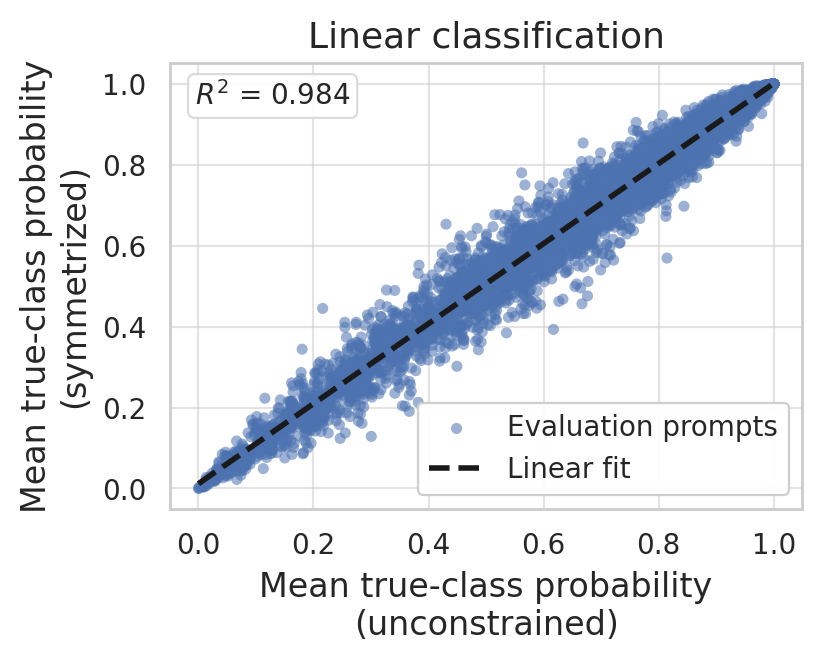

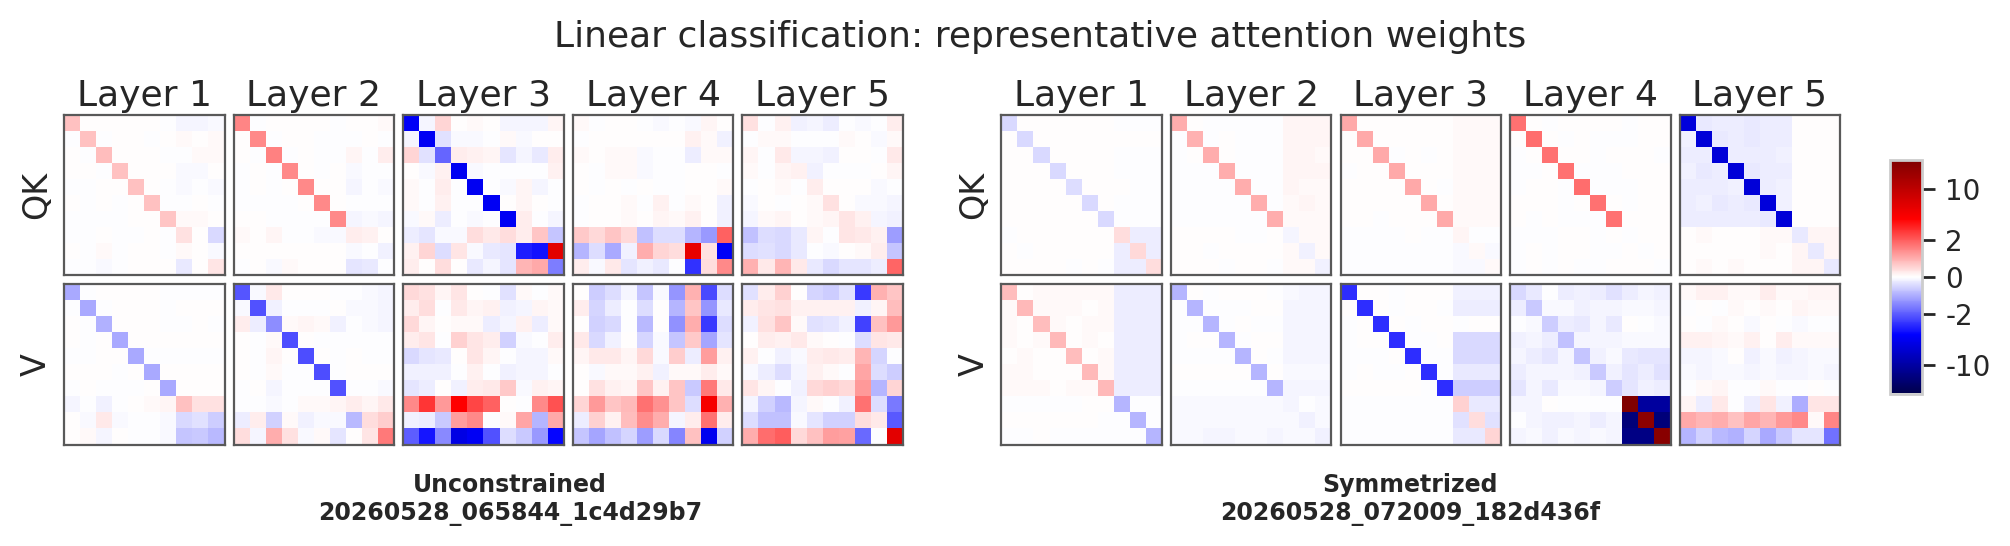

{'task': 'linear_classification',
 'r2': 0.9839882425434024,
 'slope': 0.9897760319435353,
 'intercept': 0.011623973665366298,
 'acc_unconstrained': 0.8634599924087525,
 'acc_symmetrized': 0.8674800038337708}

In [12]:
linear_classification_summary = plot_task_report("linear_classification")
linear_classification_summary["alignment"]


## Semi-Supervised Classification

This section evaluates the semi-supervised setting with `n_labeled = 8` labeled context points. The baseline panel uses label spreading with the fixed kNN and RBF hyperparameters used in the main exploratory notebook.

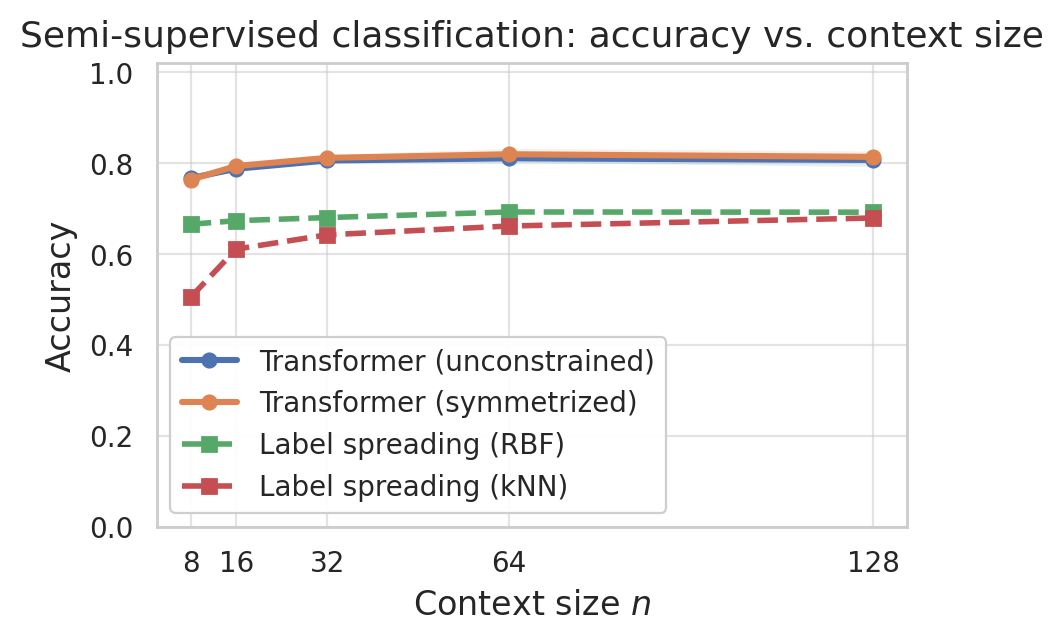

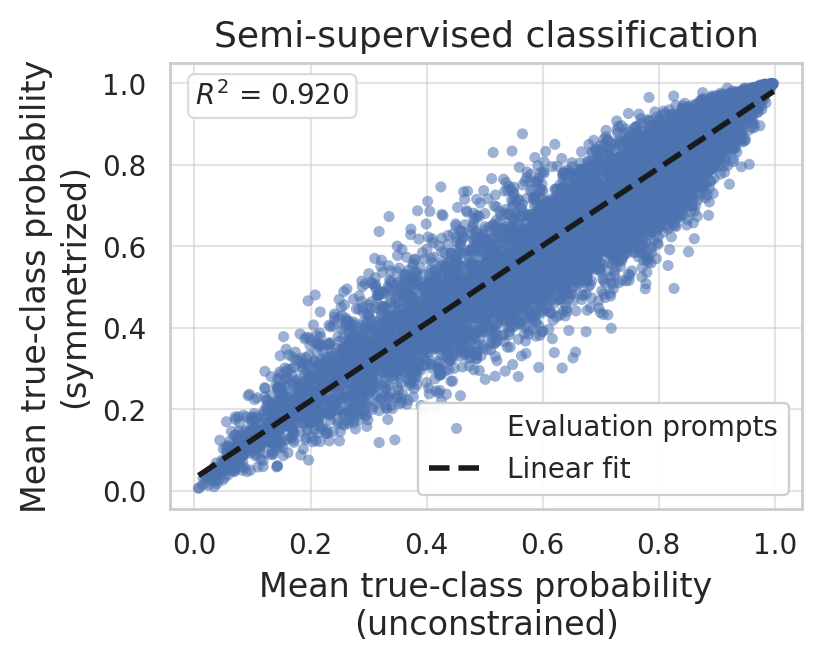

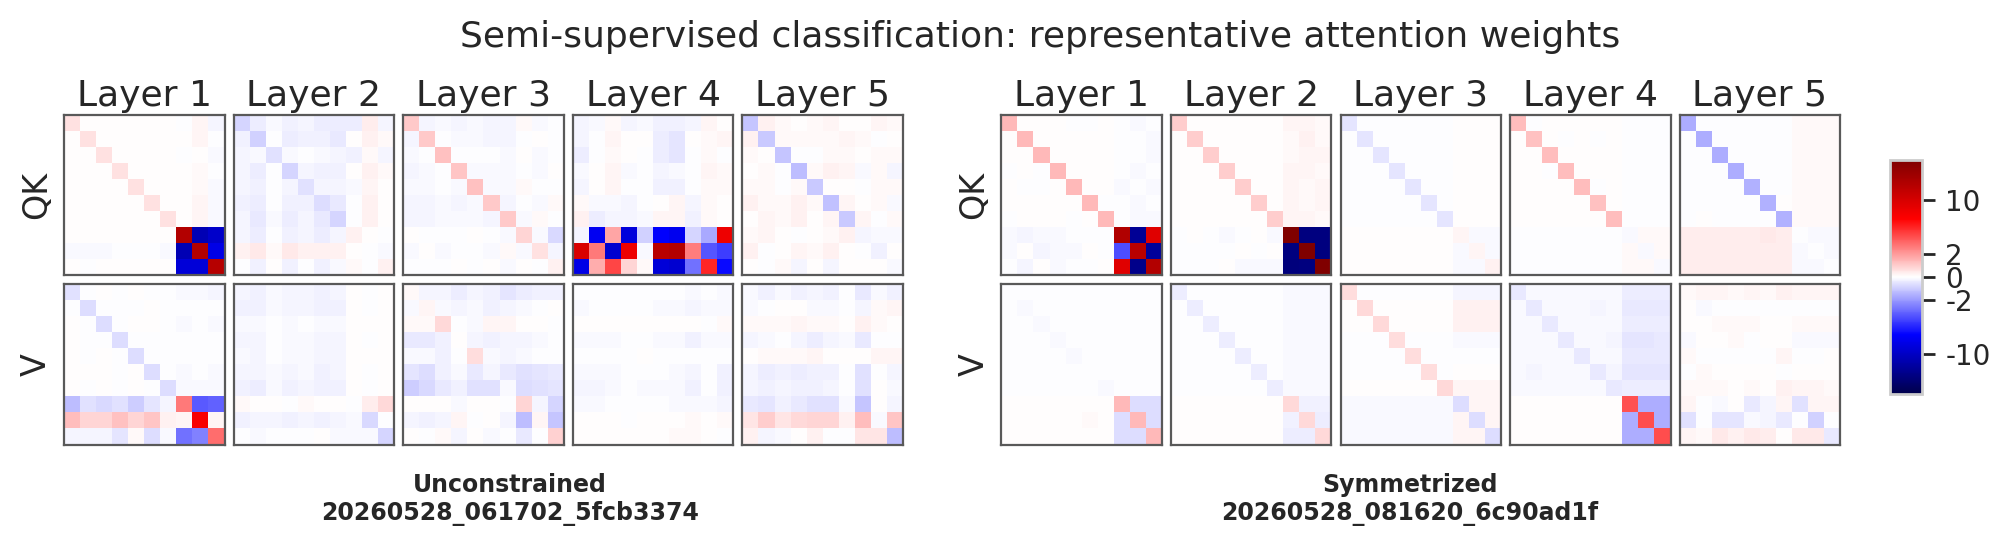

{'task': 'semi_supervised',
 'r2': 0.919853155163797,
 'slope': 0.9514758962166958,
 'intercept': 0.030645053963277262,
 'acc_unconstrained': 0.8108399987220765,
 'acc_symmetrized': 0.8198399901390075}

In [13]:
semi_supervised_summary = plot_task_report("semi_supervised")
semi_supervised_summary["alignment"]


## Voronoi Classification

This section evaluates the Voronoi classification task. The baseline panel uses a fixed 1-nearest-neighbor classifier on the labeled context points.

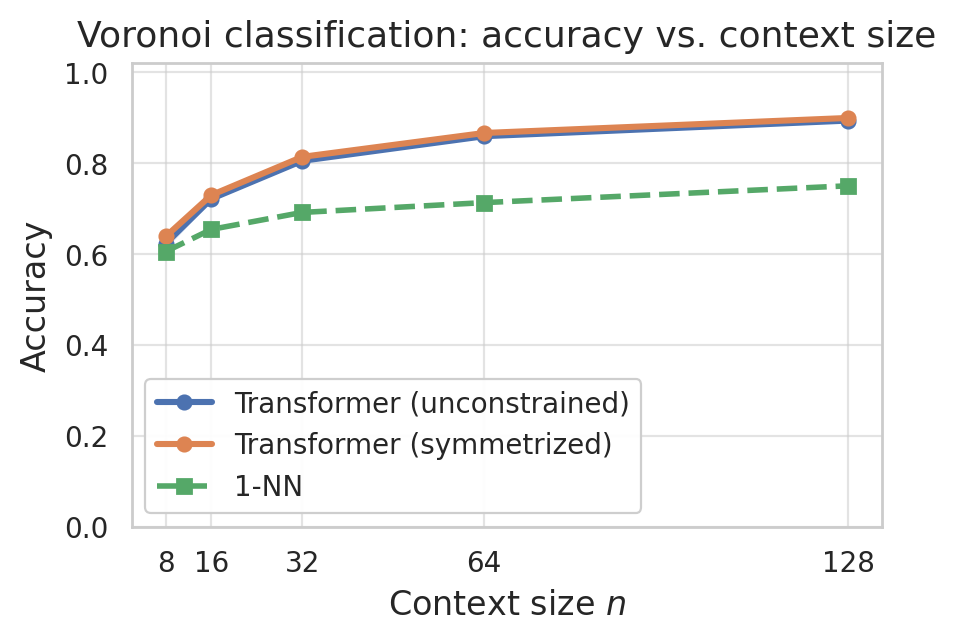

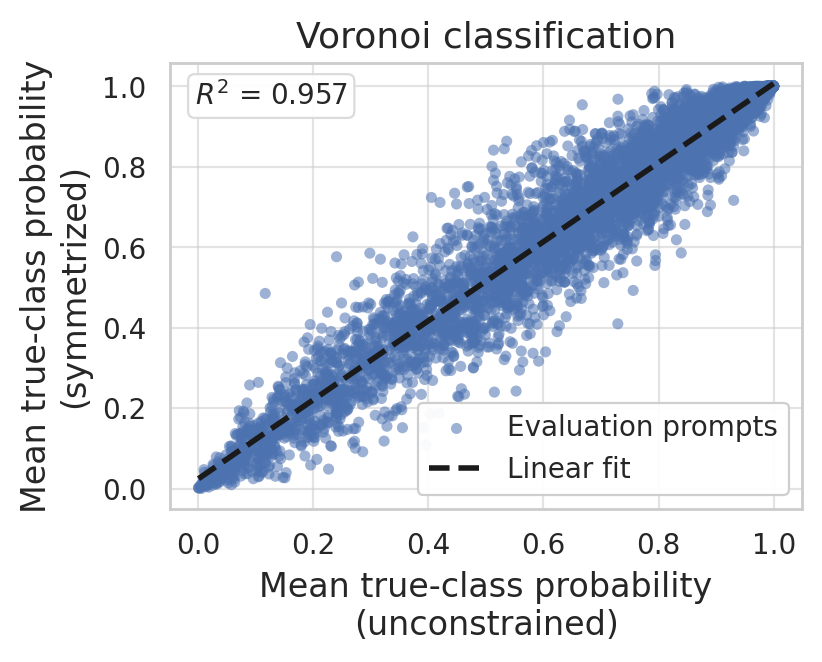

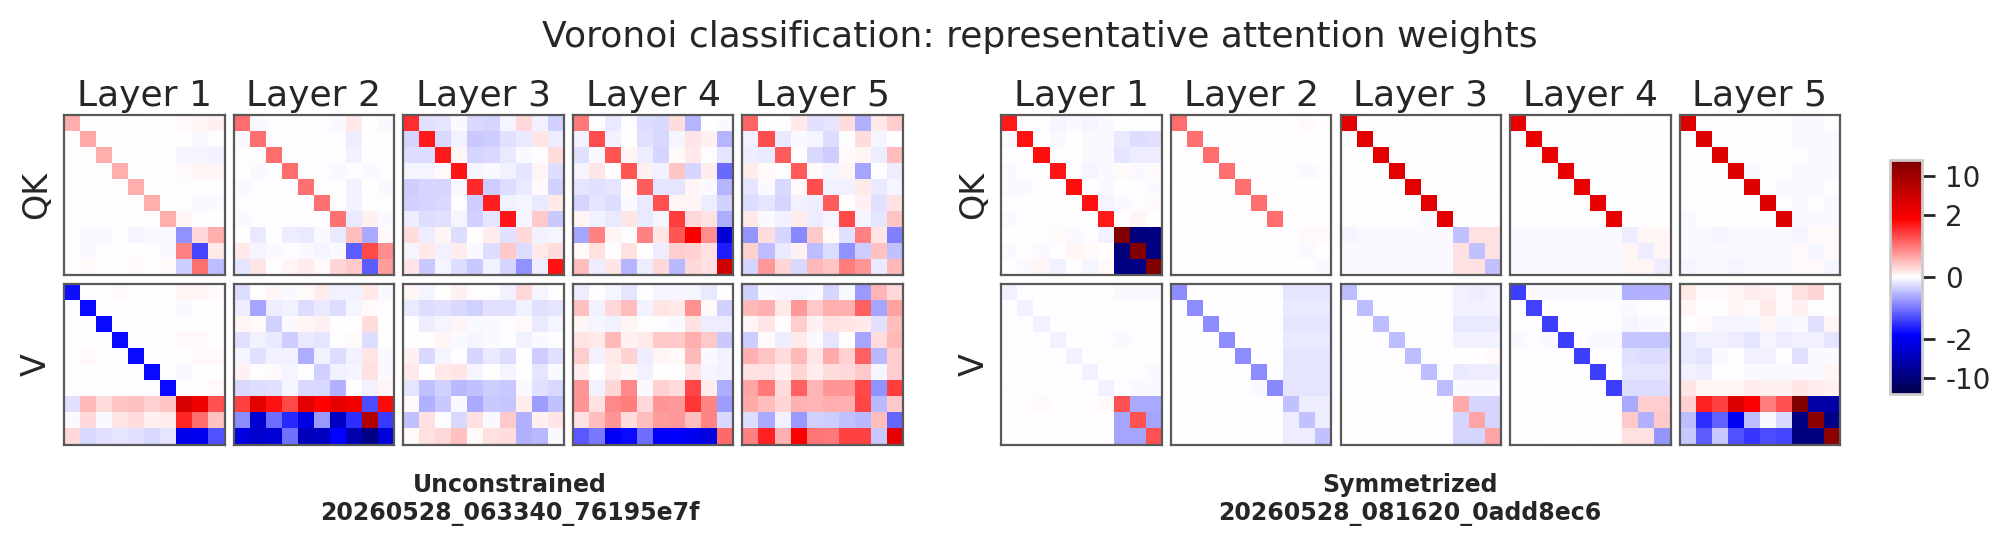

{'task': 'voronoicell',
 'r2': 0.9568793239979763,
 'slope': 0.9829706081430805,
 'intercept': 0.023689472813755358,
 'acc_unconstrained': 0.8595399975776672,
 'acc_symmetrized': 0.8666000008583069}

In [14]:
voronoicell_summary = plot_task_report("voronoicell")
voronoicell_summary["alignment"]
